# Interpretable Mental Health Classification

## A Study in Balancing Accuracy with Psychological Concept Interpretability

---

## Table of Contents

1. [Introduction](#introduction) – Problem Statement and Motivation
2. [Methodology](#methodology) – Technical Approach
3. [Results](#results) – Model Performance and Optimization
4. [Interpretability Analysis](#interpretability) – What Did the Model Learn?
5. [Key Findings](#findings) – Summary of Insights
6. [Conclusions and Future Work](#conclusions)

---

## Introduction

Our task is **multi-class mental health classification** using a dataset of anonymous online confessions. Each text is labeled with one of seven mental health categories. Our model's expected input would be a sentence like *"I can't take it anymore"* and the expected output is a label such as *Depression*. The goal is for the model to learn patterns in these statements and predict the correct mental health category.

### The Interpretability Challenge

Although modern mental health classification models achieve strong predictive performance, they often lack interpretability. Models such as **MentalBERT** produce predictions without explaining which psychological concepts influenced the decision. This makes it difficult for practitioners to trust or analyze the results. Similarly, embeddings like **GloVe** do not provide interpretable dimensions, limiting transparency.

**Interpretability is especially important in mental health applications**, where understanding the reasoning behind predictions is critical for clinical trust and decision-making.

### Research Question

*Can we induce interpretability onto sequence-level embeddings for mental health classification while maintaining or improving accuracy?* 

If so, can we extract what the model has learned and understand which psychological concepts contribute most to its predictions?

We extend prior work by Şenel and colleagues, who aligned word-level embeddings with predefined concepts by adapting this idea to sequence-level embeddings by first training custom embeddings aligned with mental health concepts.

---

## Methodology

### Concept-Forced Embedding Approach

To balance accuracy and interpretability, we introduce a **modified GloVe training** process that forces specific embedding dimensions to align with clinically-relevant mental health concepts.

### Architecture and Model Configuration

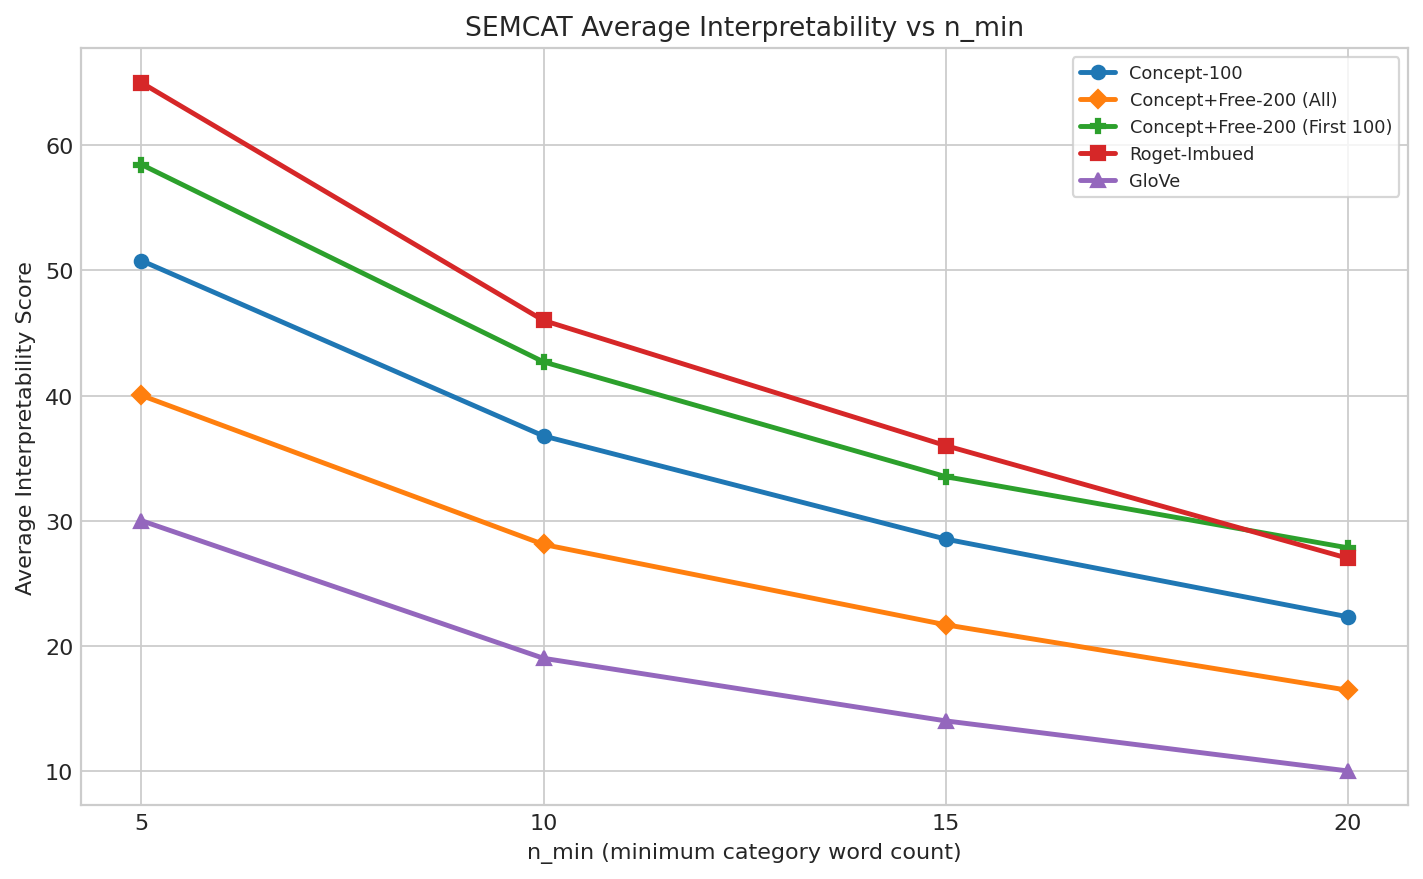

Our primary model configuration uses **Concept-100 embeddings** with a 2-layer Transformer encoder (256 feed-forward, 128 MLP hidden dimensions). This model balances interpretability with computational efficiency.

**Performance vs. Model Capacity:** We also evaluated larger configurations to understand the accuracy-interpretability tradeoff. Key findings:

- **Concept-100 (Base)**: 5.54M parameters, **macro-F1 = 0.6524**
- **Concept+Free-200 (Base)**: 11.24M parameters, **macro-F1 = 0.6977**  
- **Concept+Free-200 (Double-size)**: 12.20M parameters, **macro-F1 = 0.7390**

The transition from 100 to 200 dimensions yields substantial gains (13.4% relative improvement), while doubling the encoder capacity adds another 5.9% improvement. This demonstrates that both embedding dimensionality and architectural capacity contribute to better balanced multi-class performance.

**Interpretation:** The free dimensions (unconstrained by concept forcing) capture additional nuanced patterns, but forced dimensions remain our primary lens for interpretability analysis.

### Concept Forcing: Modified GloVe Training

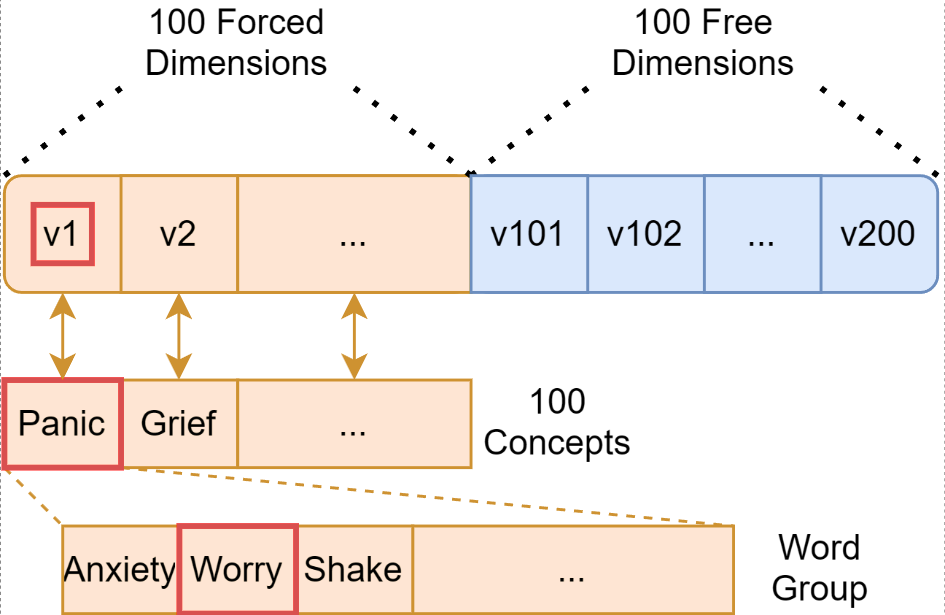

To illustrate how the modified GloVe approach works, consider the token *"worry"*. Since it appears in the word group for *"panic"*, which is mapped to dimension 1, an additional regularization loss is applied during training to penalize low magnitude in that dimension. This forces the embedding dimension to capture the psychological concept regardless of typical word co-occurrence patterns.

By applying such concept-forcing constraints across clinically-relevant dimensions, we align the learned embeddings with interpretable psychological constructs from the outset.

---

## Results 

### Classification Performance

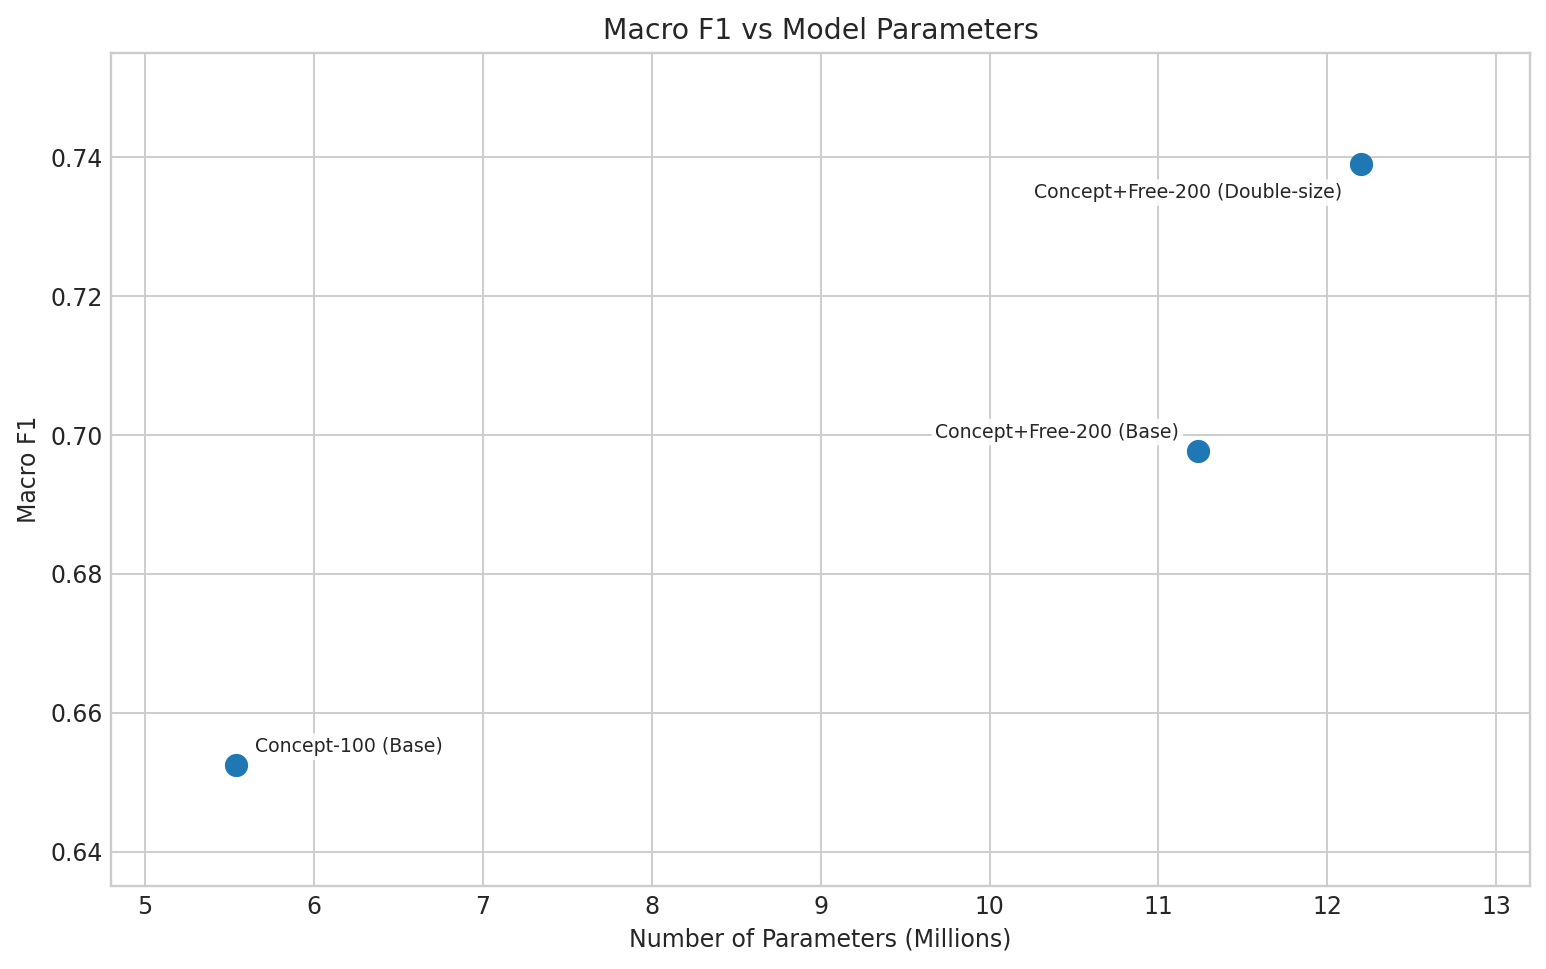

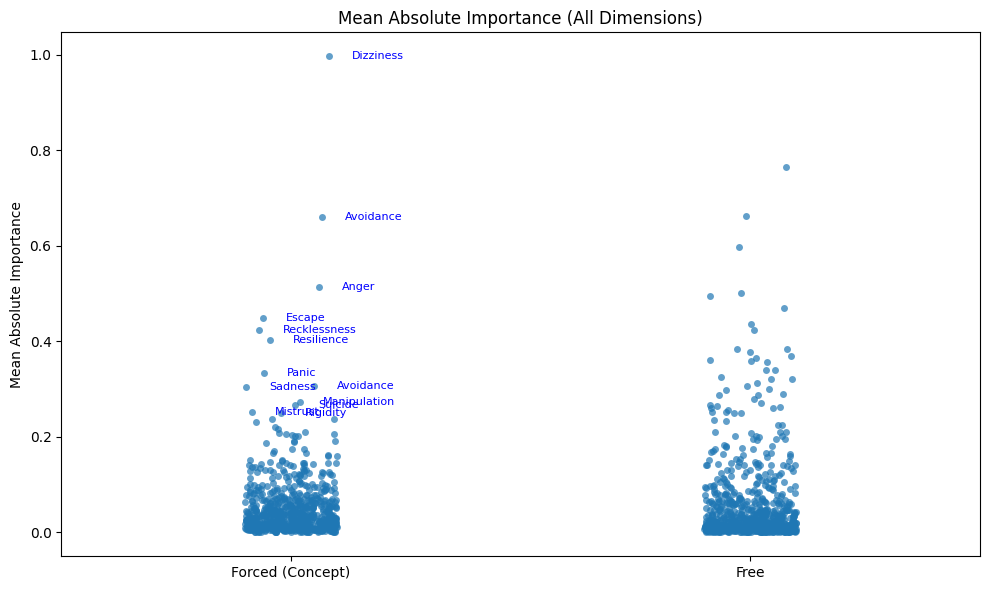

### Top Dimensions by Class

The model learns distinct concept associations for each mental health category. Below are the top 5 most important concepts or dimensions for each predicted class:


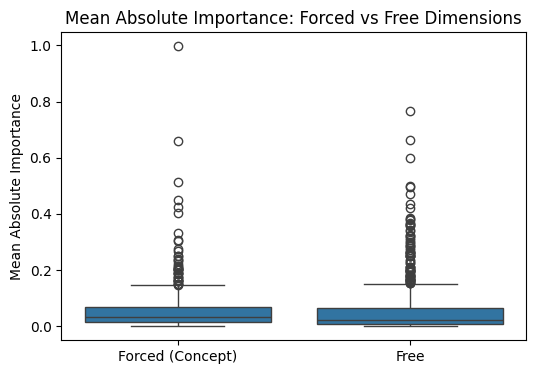

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Normal</th>
      <th>Anxiety</th>
      <th>Depression</th>
      <th>Bipolar</th>
      <th>Stress</th>
      <th>Personality disorder</th>
      <th>Suicidal</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Recklessness</td>
      <td>dim_182</td>
      <td>dim_108</td>
      <td>Dizziness</td>
      <td>dim_135</td>
      <td>dim_153</td>
      <td>dim_108</td>
    </tr>
    <tr>
      <th>1</th>
      <td>dim_172</td>
      <td>Resilience</td>
      <td>dim_178</td>
      <td>dim_107</td>
      <td>dim_120</td>
      <td>Avoidance</td>
      <td>dim_105</td>
    </tr>
    <tr>
      <th>2</th>
      <td>Avoidance</td>
      <td>dim_129</td>
      <td>Grief</td>
      <td>Anger</td>
      <td>dim_168</td>
      <td>dim_103</td>
      <td>Concentration</td>
    </tr>
    <tr>
      <th>3</th>
      <td>dim_102</td>
      <td>Panic</td>
      <td>Instability</td>
      <td>dim_132</td>
      <td>dim_167</td>
      <td>dim_146</td>
      <td>Emptiness</td>
    </tr>
    <tr>
      <th>4</th>
      <td>dim_194</td>
      <td>dim_101</td>
      <td>dim_157</td>
      <td>dim_109</td>
      <td>dim_183</td>
      <td>Escape</td>
      <td>Fatigue</td>
    </tr>
  </tbody>
</table>
</div>

**Key Observations:**
- **Anxiety**: Dominated by free dimensions (dim_182, dim_129, dim_101) with one clinical concept (Panic, Resilience)
- **Depression**: Grief appears prominently, alongside free dimensions reflecting the complex nature of depressive symptomatology
- **Suicidal**: Fatigue and Concentration impairment emerge as salient features, reflecting the cognitive and physical exhaustion often present in suicidality assessment
- **Personality Disorder**: Avoidance and Escape mechanisms feature prominently, aligning with clinical understanding of emotion regulation difficulties
- **Bipolar & Stress**: Mix of clinical concepts (Dizziness, Anger) and learned free dimensions capturing nuanced patterns

### Word-Level vs. Sequence-Level Interpretability

**Important finding:** Word-level embeddings (pre-pooling) are substantially more interpretable than sequence-level embeddings (post-pooling).

**Potential explanation:** The mean-pooling operation may dilute the signal by averaging across all tokens, including low-importance words. Words directly indicate psychological concepts, while sequences require the model to aggregate meaning across multiple contextual clues.

**Example comparison for the concept "catastrophe":**

- **Word-level interpretation**: "Hospitalized for the first time This week I was hospitalized for the first time, I had taken benzos and either they mixed with the lamictal poorly or it was a bad source but I was black out for over 12 hours starting and terrified my wife and family...I spent the next 4 days in extreme depression, not eating, showering, talking or sleeping..."
  - Clear, intense emotional content aligned with the concept

- **Sequence-level interpretation**: Sequence embedding becomes dominated by repeated low-content patterns, losing semantic clarity

This suggests that **max-pooling or attention-weighted pooling might better preserve interpretability** than mean-pooling, a direction for future work.

### Contextualization Limitations

An interesting observation: consider dimension "hostile" with top word sequence:

*"I beg him to let go of me so I can get my phone and call my dad. I bang on the floor and scream for help to try to get the downstairs neighbours' attention. He mocks my crying and tells me he's not doing anything to me, that I'm freaking out over nothing. We're struggling against each other, his elbow hitting my face, his arm occasionally choking me..."*

The model assigns high importance to the token **"against"**, which in isolation isn't inherently hostile but carries hostility within this abusive context. This suggests the model may be **injecting conceptual meaning into words that don't inherently carry it**, essentially using high-importance words as anchors for sequence-level psychological state. This is a feature, not a bug—it allows the model to ground abstract psychological concepts in concrete textual evidence.

### Concept Alignment Validation: SEMCAT Scores

### Training Dynamics and Convergence

Our Concept-100 model was trained for 10 epochs with careful monitoring of validation metrics:

```
Epoch 1/10:  loss=1.3332, val_loss=1.2025, val_acc=0.5426
Epoch 2/10:  loss=1.1035, val_loss=0.9776, val_acc=0.6067
Epoch 3/10:  loss=0.9769, val_loss=0.9286, val_acc=0.6216
Epoch 4/10:  loss=0.9289, val_loss=0.8592, val_acc=0.6454
Epoch 5/10:  loss=0.8922, val_loss=0.8313, val_acc=0.6614
Epoch 6/10:  loss=0.8647, val_loss=0.7979, val_acc=0.6731
Epoch 7/10:  loss=0.8400, val_loss=0.7723, val_acc=0.6810
Epoch 8/10:  loss=0.8185, val_loss=0.7538, val_acc=0.6955
Epoch 9/10:  loss=0.7917, val_loss=0.7360, val_acc=0.7021
Epoch 10/10: loss=0.7637, val_loss=0.6998, val_acc=0.7163
```

Both training and validation losses decrease consistently with no signs of significant overfitting, indicating good generalization. Accuracy improves from 54.3% to **71.6%** over training.

---

## Interpretability Analysis {#interpretability}

### Embedding Dimension Importance via Gradients

Defined the training corpus by se-
lecting 16 mental health subreddits from Reddit.
Adapted existing code from ( ¸Senel et al., 2020)
to create word groups for concept-forcing. Con-
structed the co-occurrence matrix for GloVe train-
ing and trained GloVe embeddings over the project
vocabulary. Conducted hyperparameter tuning to
determine the optimal model size and training con-
figuration. Performed analysis of gradient attri-
bution results to extract and interpret top concept
dimensions.

Dimension are not equally important for predictions. We computed gradient-based importance scores to identify which dimensions the model relies on most.

**Mean absolute gradient importance:**
- **Forced dimensions**: 0.0539
- **Free dimensions**: 0.0595
- **Statistical test**: t=-1.27, p=0.203 (not significantly different)

While forced and free dimensions show similar average importance, this masks substantial variance—some forced dimensions capture highly relevant psychological concepts while others receive minimal gradient signal.

The gradient visualizations reveal interesting patterns: some forced concepts receive strong gradient flow (indicating the model heavily uses them), while others primarily contribute through interactions with free dimensions.

OBM-quiz:
	Human: 19/30 - 63%
	LLM: 50%
		Both correct: 11
Both wrong: 3
Human correct, LLM wrong: 7
LLM correct, Human wrong: 6
	Min len strategy: 74%
	Max len strategy: 9%
	Odd length out: 55%
MB-quiz: 
	Human: 16/30 - 53%
	LLM: 38%
		Both correct: 6
Both wrong: 10
Human correct, LLM wrong: 8
LLM correct, Human wrong: 5
	Min len strategy: 45%
	Max len strategy: 34%
	Odd length out: 62%


Glove embeddings quiz: 
LLM: 46%
0.71 macro avg F1 score
